# Chapter 7: The theorem for any function

Checks [chapter 7](../../book/07-any-function.md) on a model that is not a single sine: a sum of
four sines with fixed amplitudes and uniform random phases. Its output has the same distribution
at every input.

    squeezed_model(input) = model(squeeze_factor * input)

For squeeze factors 1, 2, 4 and 8 the notebook checks the three facts of the chapter:

- **closer**: the reach over a label range falls to `reach / squeeze_factor`;
- **steeper**: the steepest slope rises to `squeeze_factor * slope`;
- **no better**: the average loss at the start does not change.

These are measurements on one model of one kind. The proof is `squiggly_line_theorem_general`.

Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
from common import *

use_style()

## The model

Four sines of frequency 1, 2, 3 and 4 with fixed amplitudes. The phases are drawn at random, which
makes the model a random model (chapter 5). Its slope limit is the sum of frequency times amplitude.

In [2]:
AMPLITUDES = torch.tensor([0.5, 0.35, 0.25, 0.15])
FREQUENCIES = torch.arange(1, 5, dtype=torch.float64)
SQUEEZE_FACTORS = (1.0, 2.0, 4.0, 8.0)


def evaluate_model(inputs, phases):
    '''inputs: any shape; phases: (..., terms). Sum of amplitude * sin(frequency * input + phase).'''
    angles = inputs.unsqueeze(-1) * FREQUENCIES + phases
    return (AMPLITUDES * torch.sin(angles)).sum(dim=-1)


generator = torch.Generator().manual_seed(7)
base_phases = torch.rand(4, generator=generator) * TWO_PI
slope_limit = float((AMPLITUDES * FREQUENCIES).sum())

base_values = evaluate_model(torch.linspace(0, TWO_PI, 20001), base_phases)
label_band = 0.9 * float(min(base_values.max(), -base_values.min()))
print(f"slope limit {slope_limit:.3f}, label band +-{label_band:.4f}")

slope limit 2.550, label band +-0.6011


## Closer: the reach falls by the squeeze factor

The reach is the largest distance from an input to the nearest input that hits a label, over a grid
of inputs and labels in the band. The roots are found by sign changes on a fine grid, and each root
is placed by linear interpolation. The denominator of the interpolation is signed, so it must not be
clamped (a clamp here once gave reaches near 14, which is impossible for a function of period 2 pi).

In [3]:
def get_reach(phases, squeeze_factor, label_band):
    '''The largest distance from an input to the nearest input that hits a label in the band.'''
    period = TWO_PI
    grid = torch.linspace(-2 * period, 3 * period, 400001)
    values = evaluate_model(squeeze_factor * grid, phases)
    labels = torch.linspace(-label_band, label_band, 121)
    start_inputs = torch.linspace(0, period / squeeze_factor, 301)
    largest = 0.0
    for label in labels:
        shifted = values - label
        crossings = torch.nonzero(shifted[:-1] * shifted[1:] <= 0).squeeze(-1)
        left, right = grid[crossings], grid[crossings + 1]
        root_values_left, root_values_right = shifted[crossings], shifted[crossings + 1]
        denominator = root_values_left - root_values_right            # signed: do not clamp it
        fraction = root_values_left / torch.where(denominator == 0, torch.ones_like(denominator), denominator)
        roots = left + fraction * (right - left)
        positions = torch.searchsorted(roots, start_inputs)
        low = roots[(positions - 1).clamp(0, len(roots) - 1)]
        high = roots[positions.clamp(0, len(roots) - 1)]
        nearest = torch.minimum((start_inputs - low).abs(), (high - start_inputs).abs())
        largest = max(largest, float(nearest.max()))
    return largest


def get_steepest_slope(phases, squeeze_factor):
    grid = torch.linspace(0, TWO_PI, 200001, requires_grad=True)
    output = evaluate_model(squeeze_factor * grid, phases)
    (slopes,) = torch.autograd.grad(output.sum(), grid)
    return float(slopes.abs().max())


base_reach = get_reach(base_phases, 1.0, label_band)
base_slope = get_steepest_slope(base_phases, 1.0)

rows = []
for squeeze_factor in SQUEEZE_FACTORS:
    reach = get_reach(base_phases, squeeze_factor, label_band)
    slope = get_steepest_slope(base_phases, squeeze_factor)
    rows.append({"squeeze_factor": squeeze_factor, "reach": reach, "reach_times_factor": reach * squeeze_factor,
                 "steepest_slope": slope, "slope_over_factor": slope / squeeze_factor,
                 "slope_limit_bound": squeeze_factor * slope_limit})

report("closer: reach times the squeeze factor stays at the original reach",
       all(abs(row["reach_times_factor"] - base_reach) < 0.02 * base_reach for row in rows),
       ", ".join(f"x{row['squeeze_factor']:g}: {row['reach']:.4f}" for row in rows))

[PASS] closer: reach times the squeeze factor stays at the original reach  (x1: 2.8112, x2: 1.4056, x4: 0.7028, x8: 0.3514)


True

## Steeper: the slope grows by the squeeze factor

The steepest slope of the squeezed model is the squeeze factor times the original steepest slope, and
never more than `squeeze_factor * slope_limit`.

In [4]:
report("steeper: the steepest slope is the squeeze factor times the original slope, and within "
       "squeeze_factor * slope_limit",
       all(abs(row["slope_over_factor"] - base_slope) < 1e-3 * base_slope and
           row["steepest_slope"] <= row["slope_limit_bound"] + 1e-9 for row in rows),
       f"original steepest slope {base_slope:.3f} <= slope limit {slope_limit:.3f}")
print("steepest slopes:", ", ".join(f"{row['steepest_slope']:.2f}" for row in rows))

[PASS] steeper: the steepest slope is the squeeze factor times the original slope, and within squeeze_factor * slope_limit  (original steepest slope 2.125 <= slope limit 2.550)
steepest slopes: 2.13, 4.25, 8.50, 17.00


## No better: the average loss at the start does not change

Squeezing only changes which input is read. The output has the same distribution at every input, so
the marginals are the same and, by chapter 5, so is the average loss. The average is over 400,000
random draws of the phases, on four data points. The exact value is the mean of `label^2` plus half
the sum of the squared amplitudes.

In [5]:
data = [(0.4, 0.3), (1.1, -0.5), (2.9, 0.6), (5.0, 0.1)]
draw_count = 400000
phases = torch.rand(draw_count, 4, generator=generator) * TWO_PI

loss_rows = []
for squeeze_factor in SQUEEZE_FACTORS:
    total = 0.0
    for point_x, label in data:
        outputs = evaluate_model(torch.tensor(squeeze_factor * point_x), phases)
        total += float(((label - outputs) ** 2).mean())
    loss_rows.append({"squeeze_factor": squeeze_factor, "average_loss": total / len(data)})

expected_loss = sum(label ** 2 + float((AMPLITUDES ** 2).sum()) / 2 for _, label in data) / len(data)
largest_gap = max(abs(row["average_loss"] - expected_loss) for row in loss_rows)
report("no better: the average loss is the same at every squeeze factor", largest_gap < 1e-3,
       f"expected {expected_loss:.4f}, largest gap {largest_gap:.1e}")
print("average loss:", ", ".join(f"{row['average_loss']:.4f}" for row in loss_rows))

[PASS] no better: the average loss is the same at every squeeze factor  (expected 0.4062, largest gap 2.5e-04)
average loss: 0.4063, 0.4063, 0.4065, 0.4062


## Check yourself

The chapter squeezes a model with reach 2 and slope limit 1 by 10, then asks between which two numbers
the nearest distance lies when the vertical error is 1. The cell squeezes a line of slope 1 by 10 (slope
limit 10) and measures the nearest distance to a point at vertical error 1.


In [6]:
squeezed_line = lambda inputs: 10.0 * inputs
squeezed_nearest = get_nearest_distance(squeezed_line, 0.0, 1.0, 10.0, resolution=1e-5, include_foot=False)
report("vertical error 1 after squeezing by 10: the nearest distance is 1 / sqrt(101) = 0.0995 on a line, and at most 0.2",
       abs(squeezed_nearest - 1 / math.sqrt(101)) < 1e-6 and squeezed_nearest <= 2 / 10,
       f"measured {squeezed_nearest:.5f}")


[PASS] vertical error 1 after squeezing by 10: the nearest distance is 1 / sqrt(101) = 0.0995 on a line, and at most 0.2  (measured 0.09950)


True

## Figure: one model squeezed by 1, 2 and 4

Written to `book/figures/07-squeeze.png`. The blue arrow is the reach and the dashed line is the edge
of the label band.

wrote book/figures/07-squeeze.png


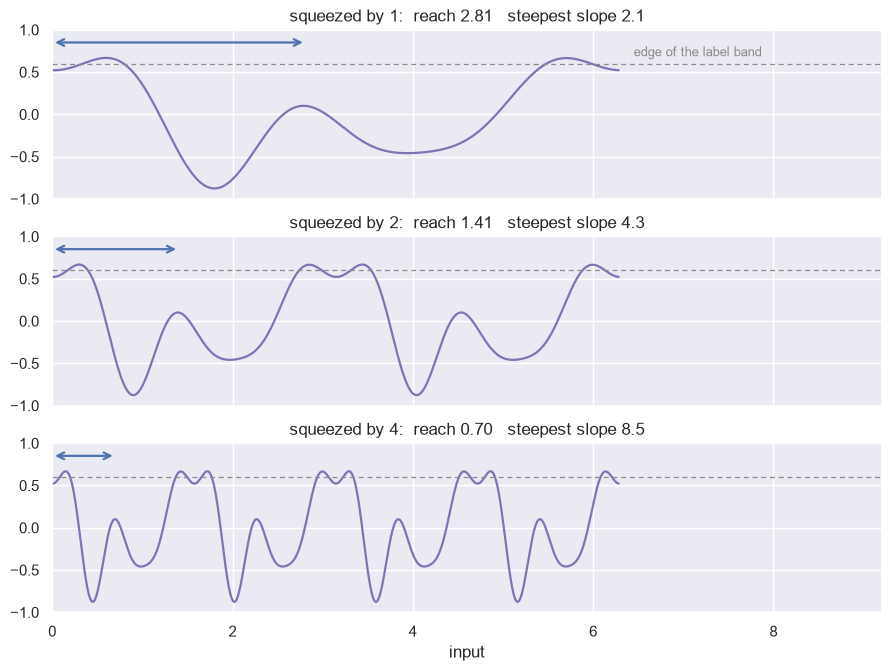

In [7]:
xs = torch.linspace(0, TWO_PI, 6000)

figure, axes = plt.subplots(3, 1, figsize=(8.8, 6.6), sharex=True, sharey=True, constrained_layout=True)
for axis, row in zip(axes, rows[:3]):
    squeeze_factor = row["squeeze_factor"]
    sns.lineplot(x=xs.numpy(), y=evaluate_model(squeeze_factor * xs, base_phases).numpy(),
                 color=MODEL, linewidth=1.6, ax=axis)
    axis.axhline(label_band, color=MUTED, linewidth=0.9, linestyle=(0, (4, 3)))
    axis.set_xlim(0, 9.2)
    axis.set_title(f"squeezed by {squeeze_factor:g}:  reach {row['reach']:.2f}   steepest slope {row['steepest_slope']:.1f}")
    axis.annotate("", xy=(row["reach"], 0.85), xytext=(0, 0.85),
                  arrowprops={"arrowstyle": "<->", "color": NEAREST, "linewidth": 1.6})
axes[0].set_ylim(-1.0, 1.0)
axes[0].text(6.45, label_band + 0.05, "edge of the label band", color=MUTED, ha="left", va="bottom", fontsize=9)
axes[-1].set_xlabel("input")
save_figure(figure, "07-squeeze")
plt.show()

## Figure: before and after squeezing by 8

Written to `book/figures/07-before-and-after-squeeze.png`. Each bar is relative to the model: the reach
falls to one eighth, the steepest slope rises eight times, and the average loss at the start stays at 1.

wrote book/figures/07-before-and-after-squeeze.png


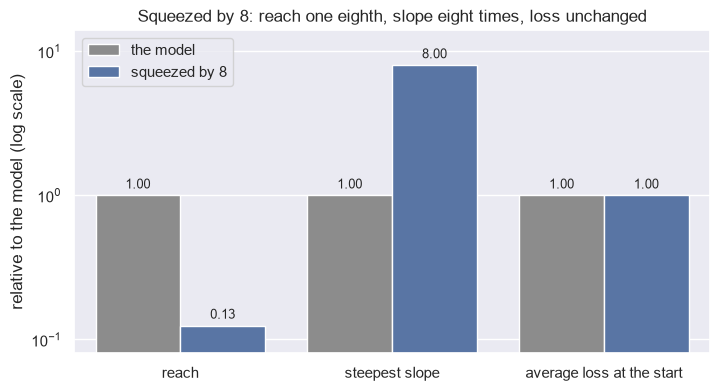

In [8]:
import pandas as pd

base_row, last_row = rows[0], rows[-1]
relative = {
    "reach": last_row["reach"] / base_row["reach"],
    "steepest slope": last_row["steepest_slope"] / base_row["steepest_slope"],
    "average loss at the start": loss_rows[-1]["average_loss"] / loss_rows[0]["average_loss"],
}
frame = pd.DataFrame([{"quantity": name, "version": "the model", "relative value": 1.0} for name in relative] +
                     [{"quantity": name, "version": "squeezed by 8", "relative value": value}
                      for name, value in relative.items()])

figure, axis = plt.subplots(figsize=(8.2, 4.2))
sns.barplot(data=frame, x="quantity", y="relative value", hue="version",
            palette={"the model": BEFORE, "squeezed by 8": NEAREST}, ax=axis)
for container in axis.containers:
    axis.bar_label(container, fmt="%.2f", padding=3, fontsize=9)
axis.set_yscale("log")
axis.set_ylim(0.08, 14)
axis.set_xlabel("")
axis.set_ylabel("relative to the model (log scale)")
axis.set_title("Squeezed by 8: reach one eighth, slope eight times, loss unchanged")
axis.legend(loc="upper left", title=None)
save_figure(figure, "07-before-and-after-squeeze")
plt.show()